In [1]:
# ==========================================
#      EDA (Exploratory Data Analysis)
# ==========================================

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print('All libraries imported successfully!')

All libraries imported successfully!


In [3]:
df=pd.read_csv("amazon_sales_cleaned.csv")

print("Your data imported successfully!")

Your data imported successfully!


In [4]:
df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,0,INR,647.62,MUMBAI,MAHARASHTRA,400081,IN,No Promotion,False,Easy Ship
1,1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,1,INR,406.00,BENGALURU,KARNATAKA,560085,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship
2,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,Unknown
3,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008,IN,No Promotion,False,Easy Ship
4,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,1,INR,574.00,CHENNAI,TAMIL NADU,600073,IN,No Promotion,False,Unknown


In [5]:
df.tail()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by
128937,128970,406-6001380-7673107,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,JNE3697,JNE3697-KR-XL,kurta,...,1,INR,517.0,HYDERABAD,TELANGANA,500013,IN,No Promotion,False,Unknown
128938,128971,402-9551604-7544318,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,SET401,SET401-KR-NP-M,Set,...,1,INR,999.0,GURUGRAM,HARYANA,122004,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,Unknown
128939,128972,407-9547469-3152358,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,J0157,J0157-DR-XXL,Western Dress,...,1,INR,690.0,HYDERABAD,TELANGANA,500049,IN,No Promotion,False,Unknown
128940,128973,402-6184140-0545956,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,J0012,J0012-SKD-XS,Set,...,1,INR,1199.0,Halol,Gujarat,389350,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,Unknown
128941,128974,408-7436540-8728312,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,J0003,J0003-SET-S,Set,...,1,INR,696.0,Raipur,CHHATTISGARH,492014,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,Unknown


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128942 entries, 0 to 128941
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128942 non-null  int64  
 1   Order ID            128942 non-null  object 
 2   Date                128942 non-null  object 
 3   Status              128942 non-null  object 
 4   Fulfilment          128942 non-null  object 
 5   Sales Channel       128942 non-null  object 
 6   ship-service-level  128942 non-null  object 
 7   Style               128942 non-null  object 
 8   SKU                 128942 non-null  object 
 9   Category            128942 non-null  object 
 10  Size                128942 non-null  object 
 11  ASIN                128942 non-null  object 
 12  Courier Status      122073 non-null  object 
 13  Qty                 128942 non-null  int64  
 14  currency            128942 non-null  object 
 15  Amount              121149 non-nul

In [216]:
df.shape

(121149, 29)

In [8]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df['ship-postal-code'] = df['ship-postal-code'].astype(str)

In [9]:
df[["Date",'ship-postal-code']].dtypes

Date                datetime64[ns]
ship-postal-code            object
dtype: object

In [10]:
df.drop(columns=["index"], inplace=True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128942 entries, 0 to 128941
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128942 non-null  object        
 1   Date                128942 non-null  datetime64[ns]
 2   Status              128942 non-null  object        
 3   Fulfilment          128942 non-null  object        
 4   Sales Channel       128942 non-null  object        
 5   ship-service-level  128942 non-null  object        
 6   Style               128942 non-null  object        
 7   SKU                 128942 non-null  object        
 8   Category            128942 non-null  object        
 9   Size                128942 non-null  object        
 10  ASIN                128942 non-null  object        
 11  Courier Status      122073 non-null  object        
 12  Qty                 128942 non-null  int64         
 13  currency            128942 no

In [12]:
df.shape

(128942, 22)

In [13]:
# ==========================================
#       Cathegorical Data Analysis
# ==========================================

In [14]:
# ==========================================
#      Step 1: Status Analysis
# ==========================================

In [15]:
df['Status'].value_counts()

Status
Shipped                          77788
Shipped - Delivered to Buyer     28762
Cancelled                        18325
Shipped - Returned to Seller      1950
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

In [16]:
status_percent = df["Status"].value_counts(normalize=True) * 100
print(status_percent.round(2))

Status
Shipped                          60.33
Shipped - Delivered to Buyer     22.31
Cancelled                        14.21
Shipped - Returned to Seller      1.51
Shipped - Picked Up               0.75
Pending                           0.51
Pending - Waiting for Pick Up     0.22
Shipped - Returning to Seller     0.11
Shipped - Out for Delivery        0.03
Shipped - Rejected by Buyer       0.01
Shipping                          0.01
Shipped - Lost in Transit         0.00
Shipped - Damaged                 0.00
Name: proportion, dtype: float64


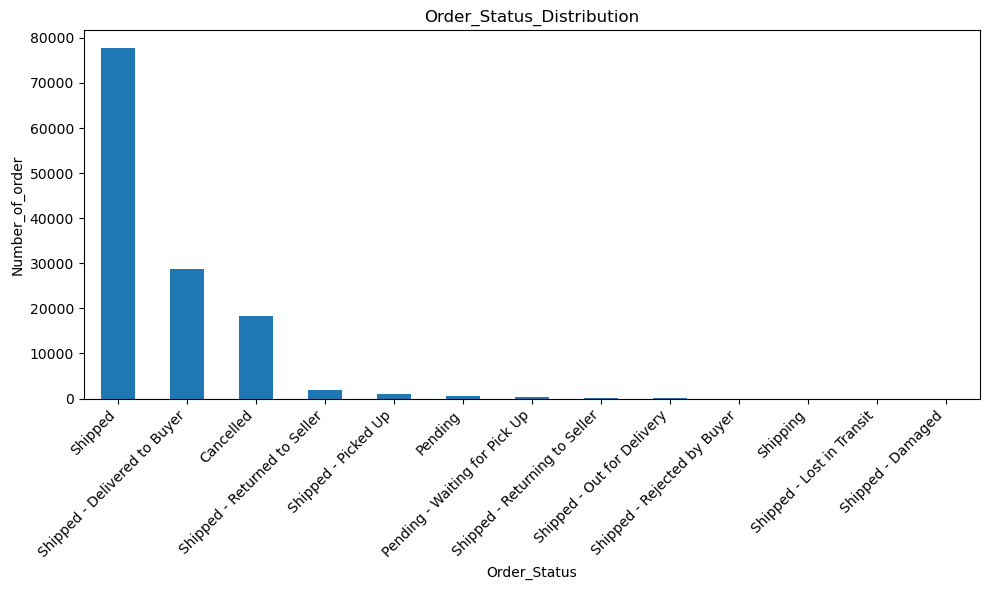

In [17]:
status_counts=df['Status'].value_counts()

plt.figure(figsize=(10,6))
status_counts.plot(kind='bar')

plt.title("Order_Status_Distribution")
plt.xlabel('Order_Status')
plt.ylabel('Number_of_order')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [18]:
# ==========================================
#      Step 2: Category Analysis
# ==========================================

In [19]:
df['Category'].value_counts()

Category
Set              50272
kurta            49859
Western Dress    15499
Top              10620
Ethnic Dress      1159
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Name: count, dtype: int64

In [20]:
category_percent =df['Category'].value_counts(normalize =True) * 100
print(category_percent.round(2))

Category
Set              38.99
kurta            38.67
Western Dress    12.02
Top               8.24
Ethnic Dress      0.90
Blouse            0.72
Bottom            0.34
Saree             0.13
Dupatta           0.00
Name: proportion, dtype: float64


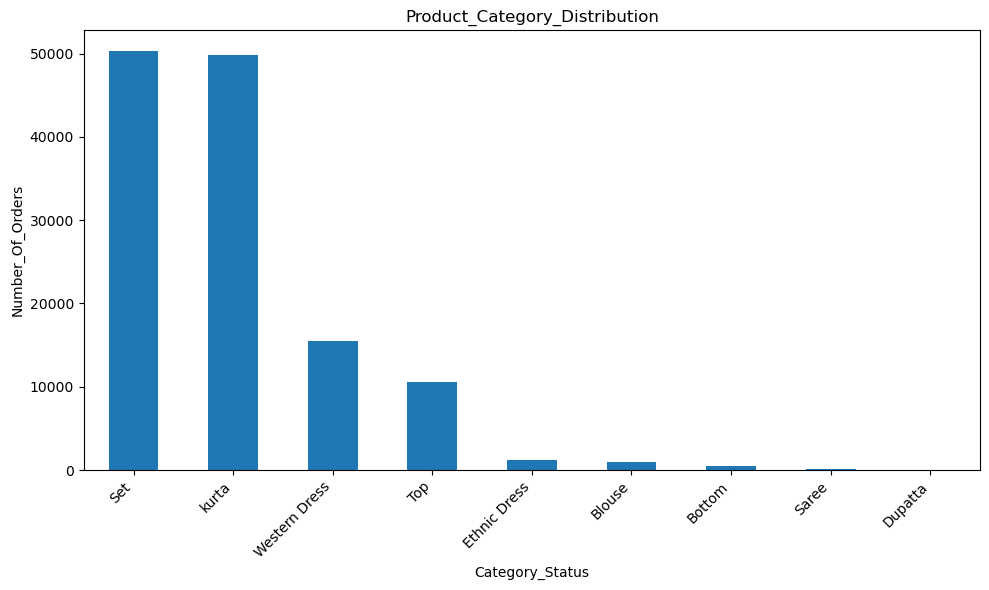

In [21]:
category_counts = df['Category'].value_counts()

plt.figure(figsize = (10,6))
category_counts.plot(kind='bar')

plt.title('Product_Category_Distribution')
plt.xlabel('Category_Status')
plt.ylabel('Number_Of_Orders')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [22]:
# ==========================================
#      Step 3: Fulfilment Analysis
# ==========================================

In [23]:
df['Fulfilment'].value_counts()

Fulfilment
Amazon      89678
Merchant    39264
Name: count, dtype: int64

In [24]:
Fulfilment_Percent = df['Fulfilment'].value_counts(normalize=True) * 100

print(Fulfilment_Percent.round(2))

Fulfilment
Amazon      69.55
Merchant    30.45
Name: proportion, dtype: float64


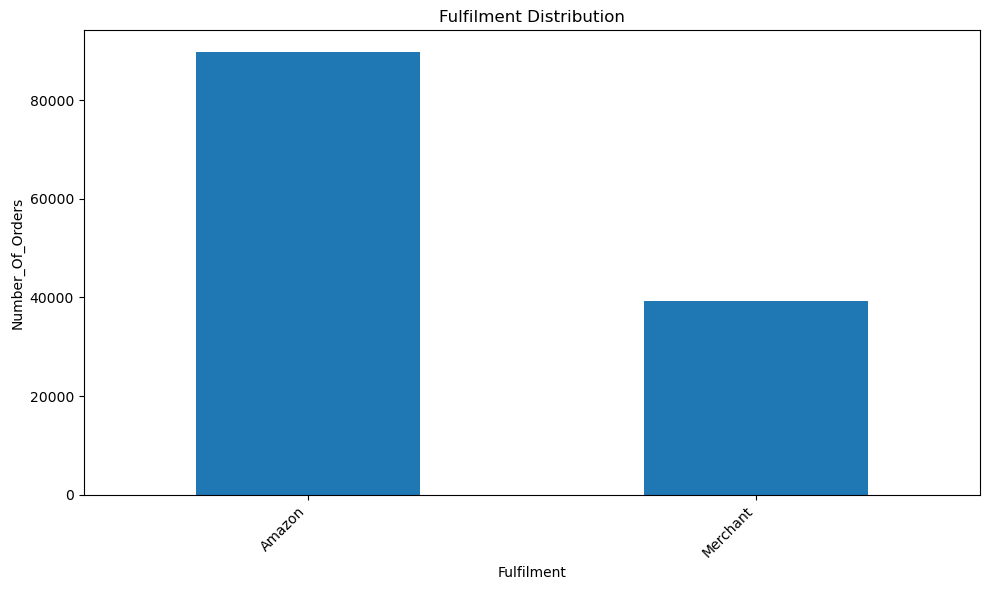

In [25]:
Fulfilment_Percent = df['Fulfilment'].value_counts()

plt.figure(figsize=(10,6))
Fulfilment_Percent.plot(kind='bar')

plt.title('Fulfilment Distribution')
plt.xlabel('Fulfilment')
plt.ylabel('Number_Of_Orders')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
#      Step 4: Sales_Channel Analysis
# ==========================================

In [27]:
df['Sales Channel '].value_counts() 

Sales Channel 
Amazon.in     128818
Non-Amazon       124
Name: count, dtype: int64

In [28]:
Sales_Channel_Percent=df['Sales Channel '].value_counts(normalize =True) *100
print(Sales_Channel_Percent.round(2))

Sales Channel 
Amazon.in     99.9
Non-Amazon     0.1
Name: proportion, dtype: float64


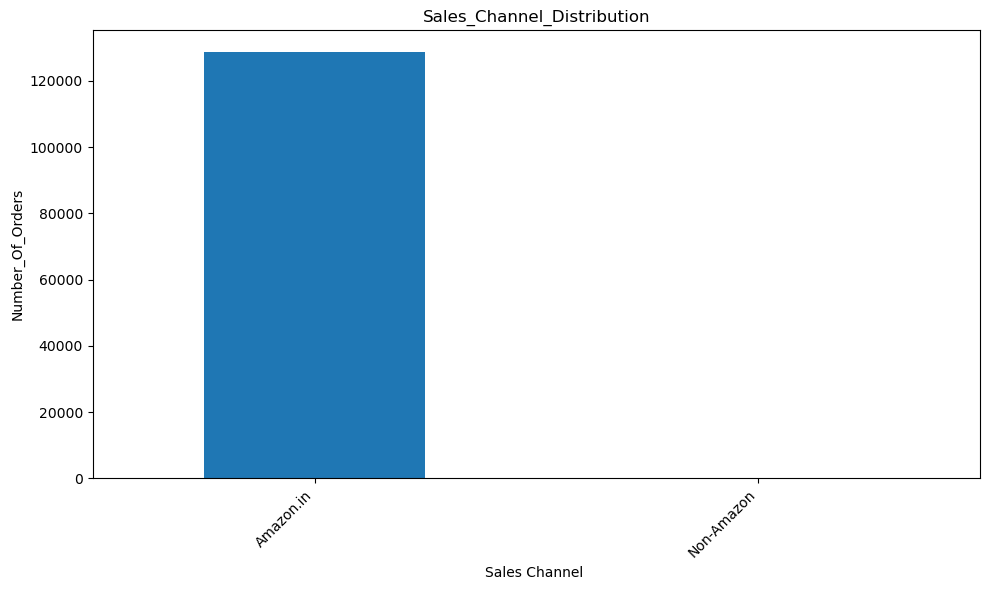

In [29]:
Sales_Channel_Percent=df['Sales Channel '].value_counts()

plt.figure(figsize=(10,6))
Sales_Channel_Percent.plot(kind='bar')

plt.title('Sales_Channel_Distribution')
plt.xlabel('Sales Channel ')
plt.ylabel("Number_Of_Orders")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Status
Status
Shipped                          77788
Shipped - Delivered to Buyer     28762
Cancelled                        18325
Shipped - Returned to Seller      1950
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

Percentage:
Status
Shipped                          60.33
Shipped - Delivered to Buyer     22.31
Cancelled                        14.21
Shipped - Returned to Seller      1.51
Shipped - Picked Up               0.75
Pending                           0.51
Pending - Waiting for Pick Up     0.22
Shipped - Returning to Seller     0.11
Shipped - Out for Delivery        0.03
Shipped - Rejected by Buyer       0.01
Shipping                          0.01
Shi

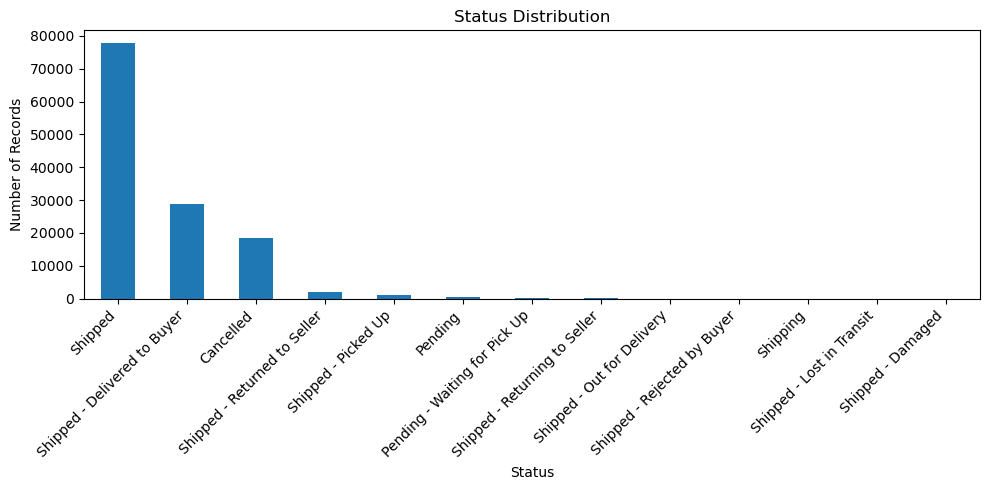


Category
Category
Set              50272
kurta            49859
Western Dress    15499
Top              10620
Ethnic Dress      1159
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Name: count, dtype: int64

Percentage:
Category
Set              38.99
kurta            38.67
Western Dress    12.02
Top               8.24
Ethnic Dress      0.90
Blouse            0.72
Bottom            0.34
Saree             0.13
Dupatta           0.00
Name: count, dtype: float64


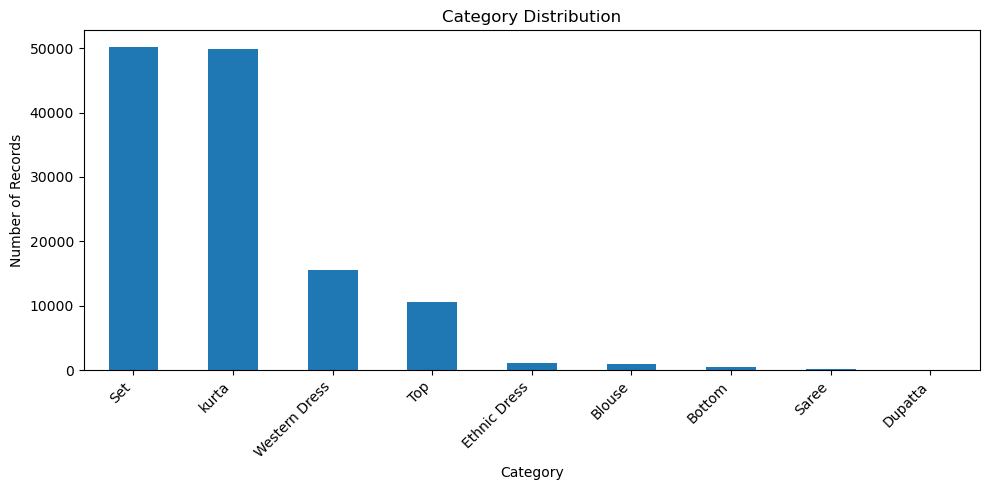


Fulfilment
Fulfilment
Amazon      89678
Merchant    39264
Name: count, dtype: int64

Percentage:
Fulfilment
Amazon      69.55
Merchant    30.45
Name: count, dtype: float64


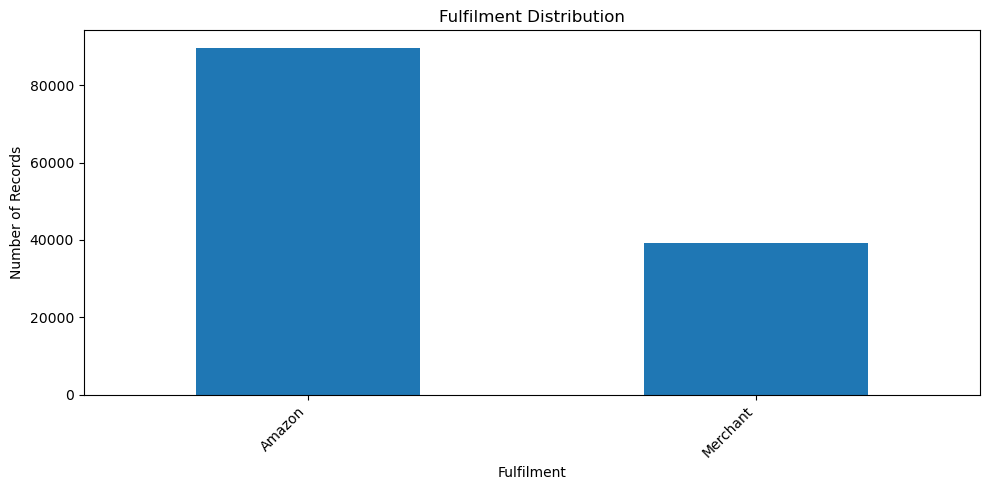


Sales Channel 
Sales Channel 
Amazon.in     128818
Non-Amazon       124
Name: count, dtype: int64

Percentage:
Sales Channel 
Amazon.in     99.9
Non-Amazon     0.1
Name: count, dtype: float64


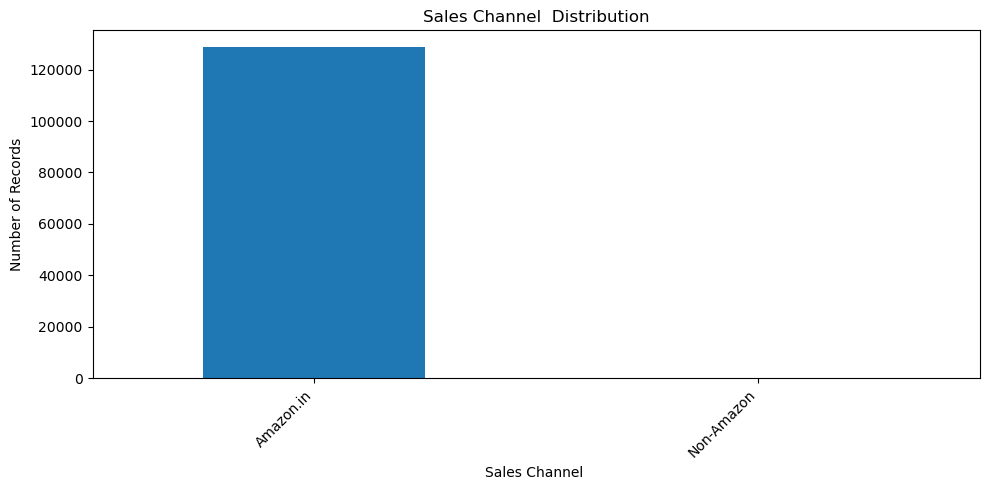


ship-service-level
ship-service-level
Expedited    88595
Standard     40347
Name: count, dtype: int64

Percentage:
ship-service-level
Expedited    68.71
Standard     31.29
Name: count, dtype: float64


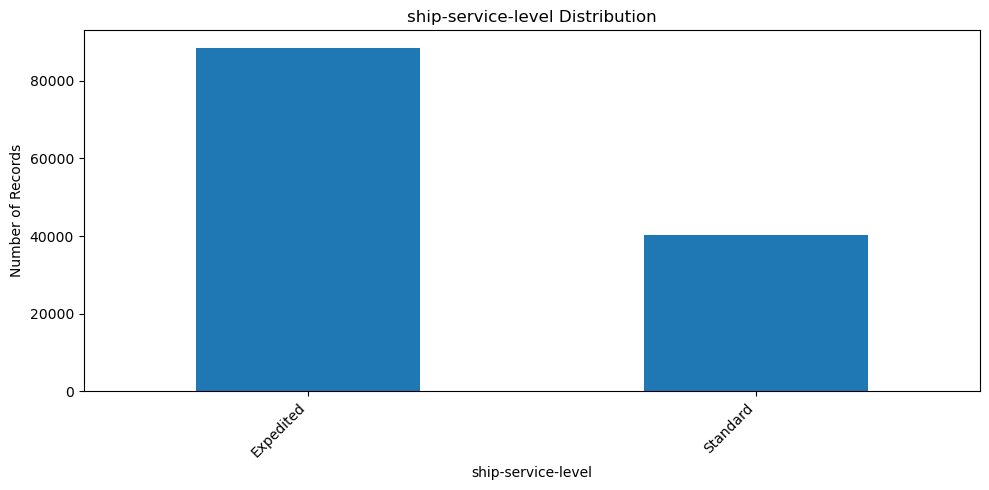

In [30]:

categorical_columns = [
    "Status",
    "Category",
    "Fulfilment",
    "Sales Channel ",
    "ship-service-level"
]

for col in categorical_columns:

    counts = df[col].value_counts()

    print("\n==============================")
    print(col)
    print("==============================")
    print(counts)

    print("\nPercentage:")
    print((counts / len(df) * 100).round(2))

    # Graph
    plt.figure(figsize=(10, 5))
    counts.plot(kind="bar")

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [31]:
# ==========================================
#       Numerical Data Analysis
# ==========================================

In [32]:
columns = [
    "Qty",
    "Amount"
]

for col in columns:
    print("\n==============================")
    print(col)
    print("==============================")

    print("Maximum:", df[col].max())
    print("Minimum:", df[col].min())
    print(f"Average: {df[col].mean():.2f}")
    print(f"Median: {df[col].median():.2f}")
    print(f"Standard Deviation: {df[col].std():.2f}")
    print(f"Skewness: {df[col].skew():.2f}")


Qty
Maximum: 15
Minimum: 0
Average: 0.90
Median: 1.00
Standard Deviation: 0.31
Skewness: -0.70

Amount
Maximum: 5584.0
Minimum: 0.0
Average: 648.57
Median: 605.00
Standard Deviation: 281.22
Skewness: 0.89


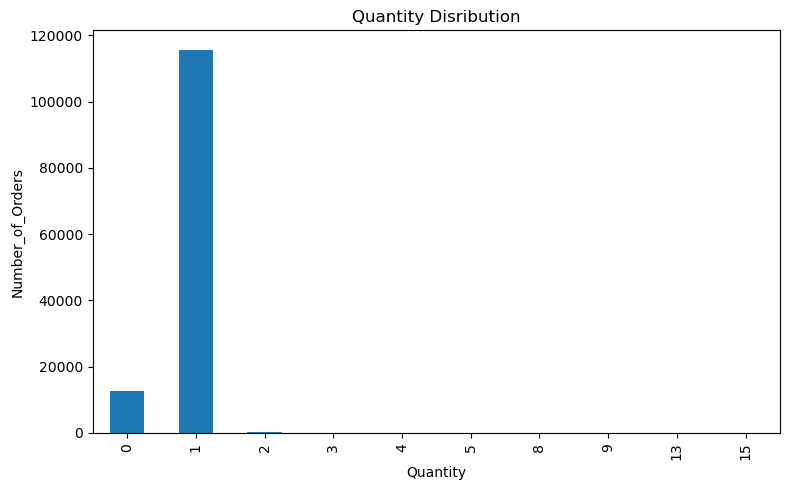

In [33]:
plt.figure(figsize=(8,5))
df['Qty'].value_counts().sort_index().plot(kind='bar')

plt.title('Quantity Disribution')
plt.xlabel('Quantity')
plt.ylabel('Number_of_Orders')
plt.tight_layout()
plt.show()

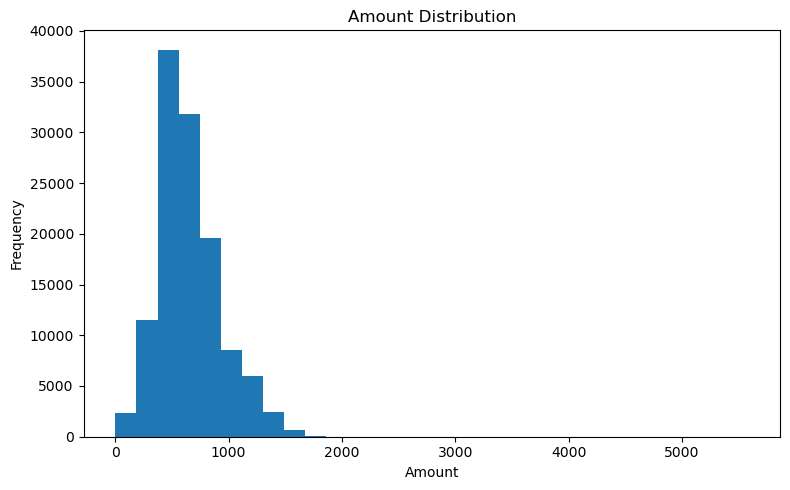

In [34]:
plt.figure(figsize=(8, 5))
df["Amount"].plot(kind="hist", bins=30)

plt.title("Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


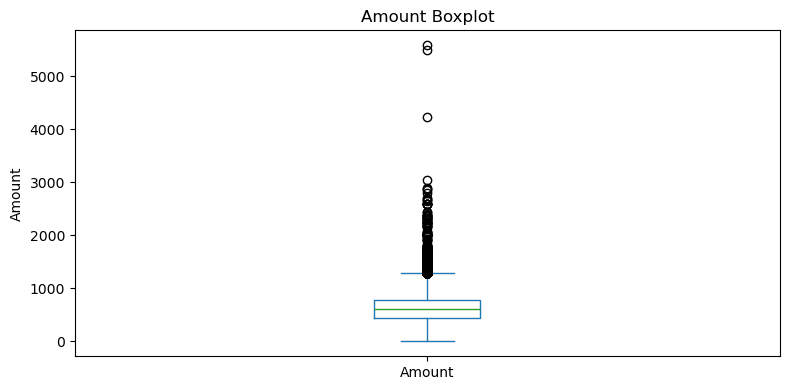

In [35]:
plt.figure(figsize=(8, 4))
df["Amount"].plot(kind="box")

plt.title("Amount Boxplot")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128942 entries, 0 to 128941
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128942 non-null  object        
 1   Date                128942 non-null  datetime64[ns]
 2   Status              128942 non-null  object        
 3   Fulfilment          128942 non-null  object        
 4   Sales Channel       128942 non-null  object        
 5   ship-service-level  128942 non-null  object        
 6   Style               128942 non-null  object        
 7   SKU                 128942 non-null  object        
 8   Category            128942 non-null  object        
 9   Size                128942 non-null  object        
 10  ASIN                128942 non-null  object        
 11  Courier Status      122073 non-null  object        
 12  Qty                 128942 non-null  int64         
 13  currency            128942 no

In [40]:
print("Minimum Date:", df["Date"].min())
print("Maximum Date:", df["Date"].max())
print("Missing Dates:", df["Date"].isna().sum())

Minimum Date: 2022-03-31 00:00:00
Maximum Date: 2022-06-29 00:00:00
Missing Dates: 0


In [44]:
df['Year'] =df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] =df['Date'].dt.month_name()
df['Day']= df['Date'].dt.day
df['Day_Name']=df['Date'].dt.day_name()

In [47]:
df[['Date', 'Year', 'Month', 'Month_Name', 'Day', 'Day_Name']].head(20)


,Date,Year,Month,Month_Name,Day,Day_Name
0,2022-04-30,2022,4,April,30,Saturday
1,2022-04-30,2022,4,April,30,Saturday
2,2022-04-30,2022,4,April,30,Saturday
3,2022-04-30,2022,4,April,30,Saturday
4,2022-04-30,2022,4,April,30,Saturday
5,2022-04-30,2022,4,April,30,Saturday
6,2022-04-30,2022,4,April,30,Saturday
7,2022-04-30,2022,4,April,30,Saturday
8,2022-04-30,2022,4,April,30,Saturday
9,2022-04-30,2022,4,April,30,Saturday


In [50]:
df['Month'].value_counts().sort_index()

Month
3      171
4    49054
5    42028
6    37689
Name: count, dtype: int64

In [52]:
df.groupby(['Month', 'Month_Name']).size().sort_index()

Month  Month_Name
3      March           171
4      April         49054
5      May           42028
6      June          37689
dtype: int64

In [53]:
daily_orders = df.groupby("Date").size()

print(daily_orders)

Date
2022-03-31     171
2022-04-01    1470
2022-04-02    1555
2022-04-03    1691
2022-04-04    1465
              ... 
2022-06-25    1026
2022-06-26    1210
2022-06-27    1111
2022-06-28    1210
2022-06-29     658
Length: 91, dtype: int64


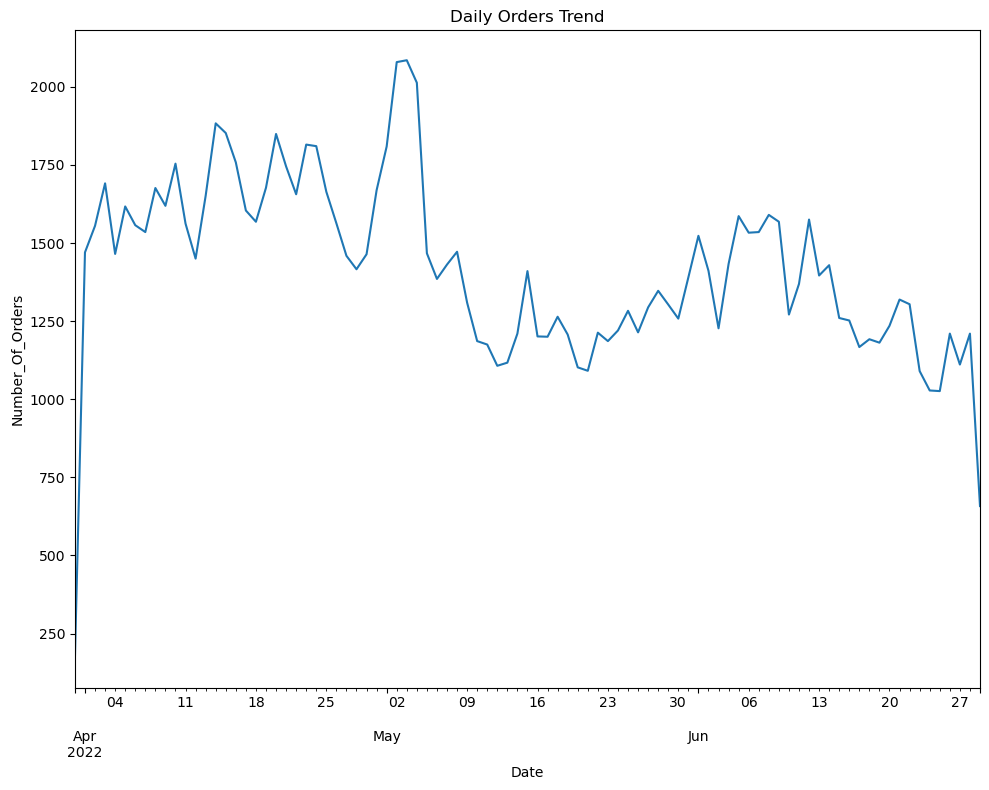

In [55]:
plt.figure(figsize=(10,8))
daily_orders.plot(kind='line')

plt.title('Daily Orders Trend')
plt.xlabel('Date')
plt.ylabel('Number_Of_Orders')
plt.tight_layout()
plt.show()

In [70]:
df['Day_Name'].value_counts().sort_index()

Day_Name
Friday       17709
Monday       18567
Saturday     18515
Sunday       19618
Thursday     17066
Tuesday      18881
Wednesday    18586
Name: count, dtype: int64

In [69]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_orders = df["Day_Name"].value_counts().reindex(day_order)

print(day_orders)

Day_Name
Monday       18567
Tuesday      18881
Wednesday    18586
Thursday     17066
Friday       17709
Saturday     18515
Sunday       19618
Name: count, dtype: int64


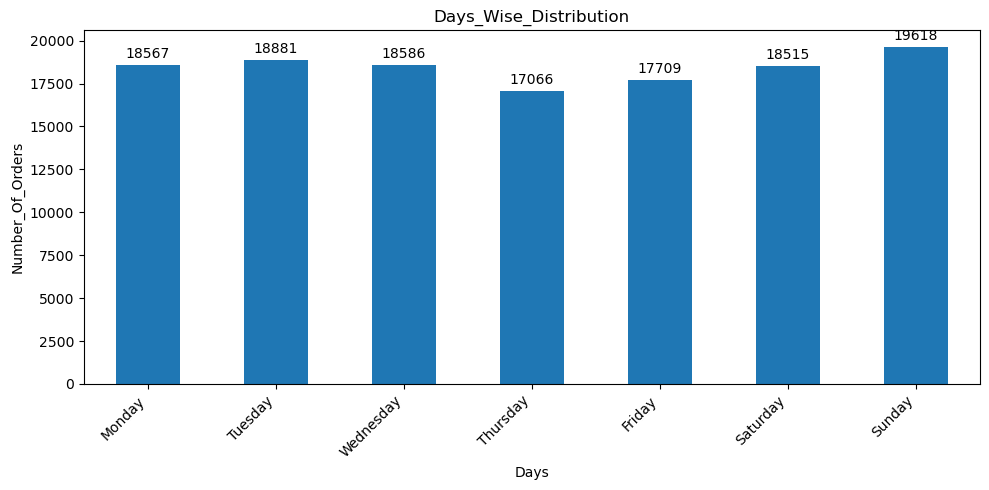

In [77]:
plt.figure(figsize=(10,5))
ax=day_orders.plot(kind="bar")

plt.title("Days_Wise_Distribution")
plt.xlabel("Days")
plt.ylabel("Number_Of_Orders")
plt.xticks(rotation=45, ha='right')
ax.bar_label(ax.containers[0], fmt='%d', padding=3)

plt.tight_layout()

plt.show()

In [82]:
month_sales=df.groupby(['Month', 'Month_Name'])['Amount'].sum().sort_index()
print(month_sales.round(2))

Month  Month_Name
3      March           101683.85
4      April         28831249.32
5      May           26219850.75
6      June          23421223.38
Name: Amount, dtype: float64


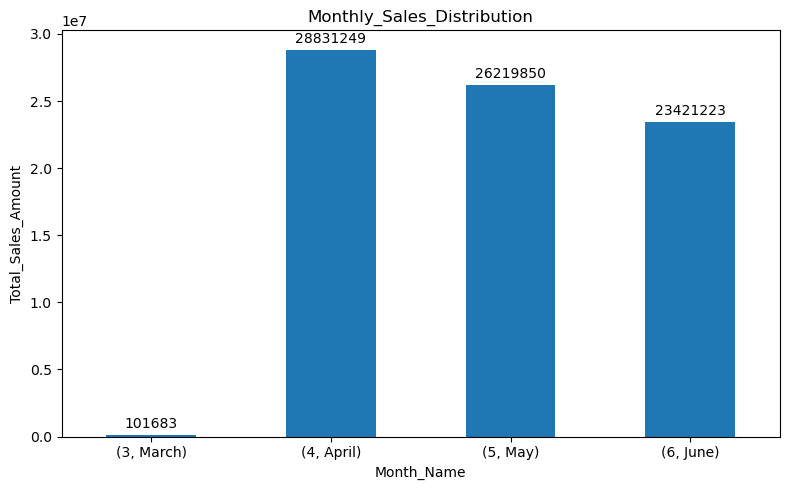

In [87]:
plt.figure(figsize=(8,5))
ax=month_sales.plot(kind='bar')

plt.title("Monthly_Sales_Distribution")
plt.xlabel("Month_Name")
plt.ylabel("Total_Sales_Amount")
plt.xticks(rotation=0)
ax.bar_label(ax.containers[0], fmt='%d', padding=3)

plt.tight_layout()
plt.show()

In [96]:
category_sales= df.groupby('Category')['Amount'].sum().sort_values(ascending=False)
print(category_sales)

Category
Set              39195176.03
kurta            21291538.70
Western Dress    11215337.69
Top               5346812.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: Amount, dtype: float64


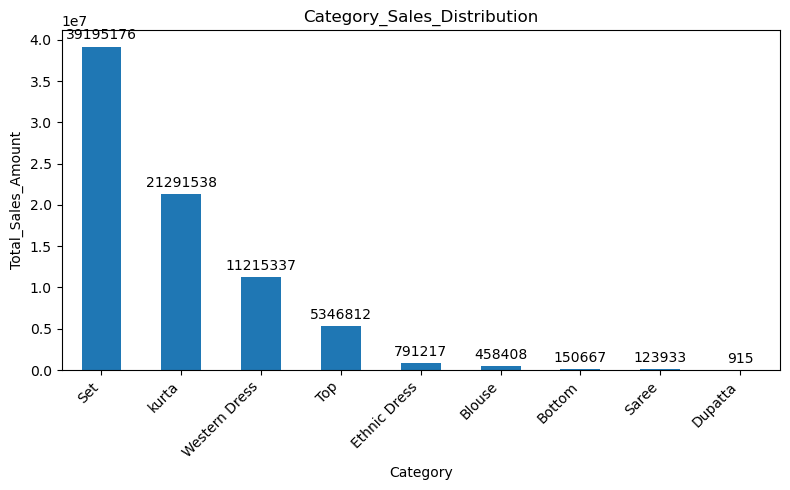

In [98]:
plt.figure(figsize=(8,5))
ax=category_sales.plot(kind='bar')

plt.title('Category_Sales_Distribution')
plt.xlabel('Category')
plt.ylabel('Total_Sales_Amount')
plt.xticks(rotation=45, ha='right')

ax.bar_label(ax.containers[0], fmt='%d', padding=3)

plt.tight_layout()
plt.show()

In [107]:
fulfilment_sales = df.groupby("Fulfilment")["Amount"].sum().sort_values(ascending=False)

print(fulfilment_sales)

Fulfilment
Amazon      54311285.0
Merchant    24262722.3
Name: Amount, dtype: float64


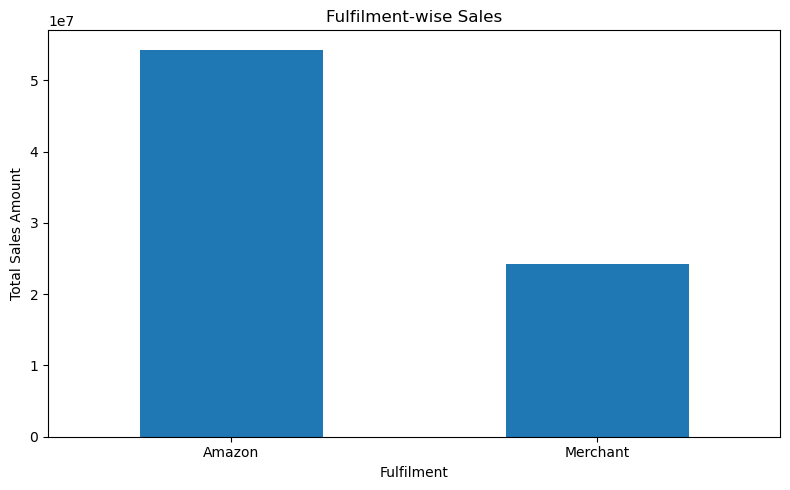

In [108]:
plt.figure(figsize=(8, 5))

fulfilment_sales.plot(kind="bar")

plt.title("Fulfilment-wise Sales")
plt.xlabel("Fulfilment")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [109]:
service_sales = df.groupby("ship-service-level")["Amount"].sum().sort_values(ascending=False)

print(service_sales)

ship-service-level
Expedited    54274317.0
Standard     24299690.3
Name: Amount, dtype: float64


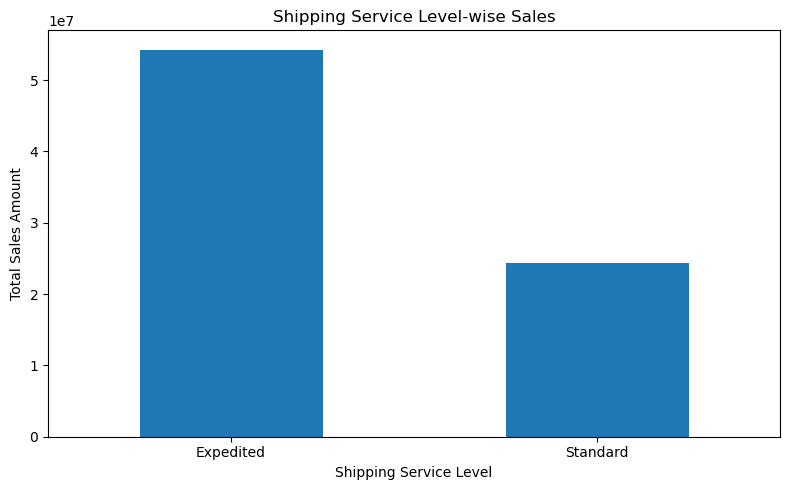

In [110]:
plt.figure(figsize=(8, 5))

service_sales.plot(kind="bar")

plt.title("Shipping Service Level-wise Sales")
plt.xlabel("Shipping Service Level")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128942 entries, 0 to 128941
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128942 non-null  object        
 1   Date                128942 non-null  datetime64[ns]
 2   Status              128942 non-null  object        
 3   Fulfilment          128942 non-null  object        
 4   Sales Channel       128942 non-null  object        
 5   ship-service-level  128942 non-null  object        
 6   Style               128942 non-null  object        
 7   SKU                 128942 non-null  object        
 8   Category            128942 non-null  object        
 9   Size                128942 non-null  object        
 10  ASIN                128942 non-null  object        
 11  Courier Status      122073 non-null  object        
 12  Qty                 128942 non-null  int64         
 13  currency            128942 no

In [116]:
df['ship-state']=df['ship-state'].str.upper()

In [143]:
state_sales=df.groupby(['ship-state'])['Amount'].sum().sort_values(ascending=False)
print(ship_sales)

ship-state
MAHARASHTRA          13335534.14
KARNATAKA            10481114.37
TELANGANA             6916615.65
UTTAR PRADESH         6816642.08
TAMIL NADU            6515650.11
DELHI                 4393522.41
KERALA                3830227.58
WEST BENGAL           3507880.44
ANDHRA PRADESH        3219831.72
HARYANA               2882092.99
GUJARAT               2728651.82
RAJASTHAN             1761131.16
MADHYA PRADESH        1592382.98
BIHAR                 1415613.32
ODISHA                1386372.39
PUNJAB                1211666.84
ASSAM                 1018136.20
UTTARAKHAND            974143.55
JHARKHAND              919088.21
GOA                    637685.85
CHHATTISGARH           570485.83
HIMACHAL PRADESH       503364.51
JAMMU & KASHMIR        456932.74
MANIPUR                213981.99
CHANDIGARH             211740.67
PUDUCHERRY             192573.24
ANDAMAN & NICOBAR      158723.62
NAGALAND               145055.67
SIKKIM                 140828.66
MEGHALAYA              119871.81

In [128]:
df["ship-state"] = df["ship-state"].str.strip().str.upper()

In [123]:
state_mapping = {
    "RAJSHTHAN": "RAJASTHAN",
    "RAJSTHAN": "RAJASTHAN",
    "RJ": "RAJASTHAN",
    
    "PONDICHERRY": "PUDUCHERRY",
    
    "ORISSA": "ODISHA",
    
    "PB": "PUNJAB",
    
    "AR": "ARUNACHAL PRADESH",
    
    "NL": "NAGALAND",
    
    "NEW DELHI": "DELHI",
    
    "PUNJAB/MOHALI/ZIRAKPUR": "PUNJAB"
}

df["ship-state"] = df["ship-state"].replace(state_mapping)

In [124]:
df['ship-state'].unique()

array(['MAHARASHTRA', 'KARNATAKA', 'PUDUCHERRY', 'TAMIL NADU',
       'UTTAR PRADESH', 'CHANDIGARH', 'TELANGANA', 'ANDHRA PRADESH',
       'RAJASTHAN', 'DELHI', 'HARYANA', 'ASSAM', 'JHARKHAND',
       'CHHATTISGARH', 'ODISHA', 'KERALA', 'MADHYA PRADESH',
       'WEST BENGAL', 'NAGALAND', 'GUJARAT', 'UTTARAKHAND', 'BIHAR',
       'JAMMU & KASHMIR', 'PUNJAB', 'HIMACHAL PRADESH',
       'ARUNACHAL PRADESH', 'MANIPUR', 'GOA', 'MEGHALAYA', 'TRIPURA',
       'LADAKH', 'DADRA AND NAGAR', 'SIKKIM', 'ANDAMAN & NICOBAR',
       'MIZORAM', 'LAKSHADWEEP', 'APO'], dtype=object)

In [134]:
df[df["ship-state"] == "APO"]

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Year,Month,Month_Name,Day,Day_Name
45174,405-0034289-0259545,2022-04-03,Cancelled,Amazon,Amazon.in,Expedited,J0077,J0077-SKD-S,Set,S,...,959121,IN,No Promotion,False,Unknown,2022,4,April,3,Sunday


In [135]:
df["ship-state"].value_counts().loc["APO"]

1

In [137]:
df['ship-state']=df['ship-state'].replace('APO', pd.NA)

In [138]:
df['ship-state'].isna().sum()

1

In [139]:
df=df.dropna(subset=['ship-state'])

In [140]:
df['ship-state'].isna().sum()

0

In [147]:
top_states=state_sales.head(20)
print(top_states)

ship-state
MAHARASHTRA       13335534.14
KARNATAKA         10481114.37
TELANGANA          6916615.65
UTTAR PRADESH      6816642.08
TAMIL NADU         6515650.11
DELHI              4393522.41
KERALA             3830227.58
WEST BENGAL        3507880.44
ANDHRA PRADESH     3219831.72
HARYANA            2882092.99
GUJARAT            2728651.82
RAJASTHAN          1761131.16
MADHYA PRADESH     1592382.98
BIHAR              1415613.32
ODISHA             1386372.39
PUNJAB             1211666.84
ASSAM              1018136.20
UTTARAKHAND         974143.55
JHARKHAND           919088.21
GOA                 637685.85
Name: Amount, dtype: float64


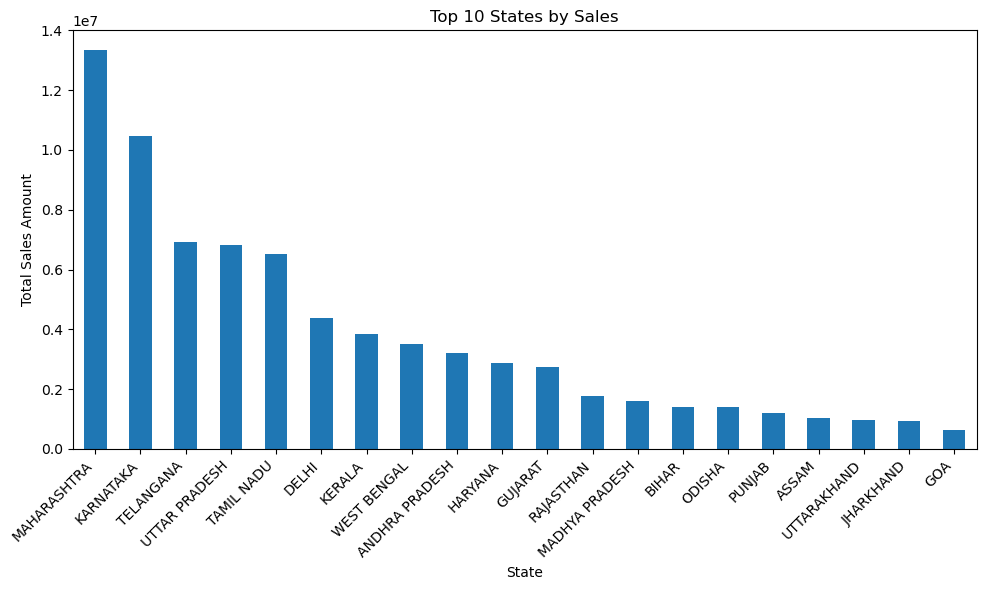

In [148]:
plt.figure(figsize=(10, 6))

top_states.plot(kind="bar")

plt.title("Top 20 States by Sales")
plt.xlabel("State")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [149]:
state_orders = df["ship-state"].value_counts().head(10)

print(state_orders)

ship-state
MAHARASHTRA       22260
KARNATAKA         17326
TAMIL NADU        11483
TELANGANA         11330
UTTAR PRADESH     10638
DELHI              7048
KERALA             6585
WEST BENGAL        5963
ANDHRA PRADESH     5430
GUJARAT            4489
Name: count, dtype: int64


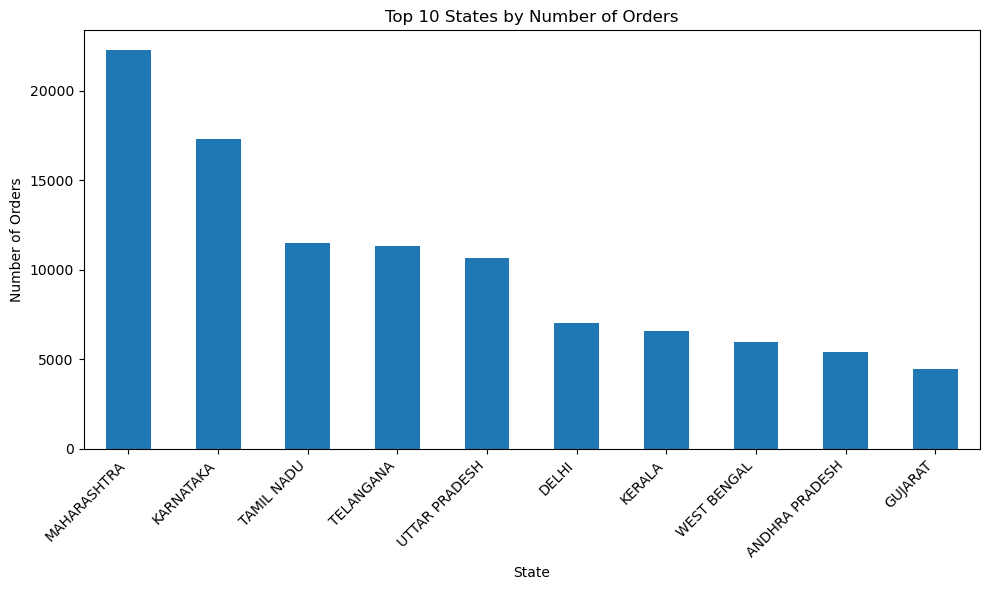

In [150]:
plt.figure(figsize=(10, 6))

state_orders.plot(kind="bar")

plt.title("Top 10 States by Number of Orders")
plt.xlabel("State")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [153]:
top_cities=df.groupby(['ship-city'])['Amount'].sum().sort_values(ascending=False)
print(top_cities)

ship-city
BENGALURU              6849664.99
HYDERABAD              4946032.82
MUMBAI                 3704461.80
NEW DELHI              3613874.78
CHENNAI                3098745.74
                          ...    
BANNUR                       0.00
Kujang                       0.00
koperkhairne                 0.00
Pune 411006                  0.00
SERAIKELA KHARSAWAN          0.00
Name: Amount, Length: 8954, dtype: float64


In [161]:
df['ship-city'].unique().sum()

"MUMBAIBENGALURUNAVI MUMBAIPUDUCHERRYCHENNAIGHAZIABADCHANDIGARHHYDERABADChennaiNOIDAAmravati.GUNTAKALJAIPURNEW DELHIGurgaonTIRUCHIRAPPALLIpuneTEZPURRANCHIBILASPURPUNEGUWAHATITHIRUVARURLUCKNOWVISAKHAPATNAMJEYPURTHIRUVANANTHAPURAMGREATER NOIDAJABALPURKOLKATAONGOLESECUNDERABADKEWALPURCUTTACKBADLAPURdimapurWARANGALDHAULPURBengaluruNAGPURTHANEDahodVIJAPURAbangaloreBERHAMPURHIMMATNAGARKolkataDEHRADUNDHARMAPURIVADODARACHAVAKKADPATNAJammuNARNAUNDAhmedabadAMBARNATHGWALIORROHTAKRAMAGUNDAMPITHORAGARHGUWAHATI, KAMRUP (M)KOLARPATIALAREWABONGAIGAONChengalpattuPERAMBALURVARANASICOIMBATORECHIRMIRIAZAMGARHKALYANMYSOREBARABANKIAMILAVIJAYAWADARAWAN AMBUJA CEMENT PLANTHERBERTPURKALAMASSERYPuri-2TIKABALIBIHARSHARIFPARAVURBASTIWALAJAPETDimapurMahendragarhNew DelhiGURUGRAMBIJNORALLAHABADVASAI VIRARMANGALURUNEW TOWNSAMBHALELAVANASURKOTTAISANGLI MIRAJ KUPWADMYSURUANKLESHWRGreater Noida WestJAMMUITANAGARKARANJANIMBAHERAImphal EastBIDHAN NAGARAHMEDABADBHUBANESWARALIGARHKOCHIBangaloreMALAPPURAMSIBSAGARGAYAKOLLAMP

In [164]:
df = df.copy()

df["ship-city-clean"] = df["ship-city"]

In [165]:
df["ship-city-clean"] = (
    df["ship-city-clean"]
    .astype("string")
    .str.strip()
    .str.upper()
)

In [166]:
print(df[["ship-city", "ship-city-clean"]].head(10))

     ship-city ship-city-clean
0       MUMBAI          MUMBAI
1    BENGALURU       BENGALURU
2  NAVI MUMBAI     NAVI MUMBAI
3   PUDUCHERRY      PUDUCHERRY
4      CHENNAI         CHENNAI
5    GHAZIABAD       GHAZIABAD
6   CHANDIGARH      CHANDIGARH
7    HYDERABAD       HYDERABAD
8    HYDERABAD       HYDERABAD
9      Chennai         CHENNAI


In [167]:
df = df[df["Amount"].notna()]

In [168]:
city_counts = df["ship-city-clean"].value_counts()

print(city_counts.head(50))

ship-city-clean
BENGALURU             11324
HYDERABAD              8591
MUMBAI                 6809
NEW DELHI              5975
CHENNAI                5959
PUNE                   4380
KOLKATA                2678
GURUGRAM               1867
THANE                  1774
NOIDA                  1540
LUCKNOW                1518
GHAZIABAD              1408
AHMEDABAD              1381
NAVI MUMBAI            1313
BANGALORE              1302
JAIPUR                  984
COIMBATORE              832
VISAKHAPATNAM           804
FARIDABAD               783
PATNA                   757
BHUBANESWAR             737
PIMPRI CHINCHWAD        710
GUWAHATI                693
NAGPUR                  690
VADODARA                669
THIRUVANANTHAPURAM      642
DEHRADUN                596
SECUNDERABAD            583
GREATER NOIDA           533
INDORE                  524
KALYAN                  522
KANPUR                  508
ERNAKULAM               485
BHOPAL                  470
RANCHI                  459
VIJA

In [177]:
cities_sales = df.groupby("ship-city")["Amount"].sum().sort_values(ascending=False)

print(cities_sales)

ship-city
BENGALURU                  6849664.99
HYDERABAD                  4946032.82
MUMBAI                     3704461.80
NEW DELHI                  3613874.78
CHENNAI                    3098745.74
                              ...    
Calicut medical college          0.00
TARBHA                           0.00
MATHABHANGA                      0.00
Dharuhera                        0.00
BALAPUR MIDC                     0.00
Name: Amount, Length: 8704, dtype: float64


In [178]:
top_cities=cities_sales.head(20)
print(top_cities)

ship-city
BENGALURU      6849664.99
HYDERABAD      4946032.82
MUMBAI         3704461.80
NEW DELHI      3613874.78
CHENNAI        3098745.74
PUNE           2338518.18
KOLKATA        1414978.87
GURUGRAM       1221618.74
THANE          1004355.29
LUCKNOW         933926.34
NOIDA           910666.98
GHAZIABAD       835633.35
AHMEDABAD       769345.70
NAVI MUMBAI     754761.81
JAIPUR          596310.22
Hyderabad       569678.95
Mumbai          518502.89
PATNA           497184.05
FARIDABAD       459168.50
BHUBANESWAR     457102.40
Name: Amount, dtype: float64


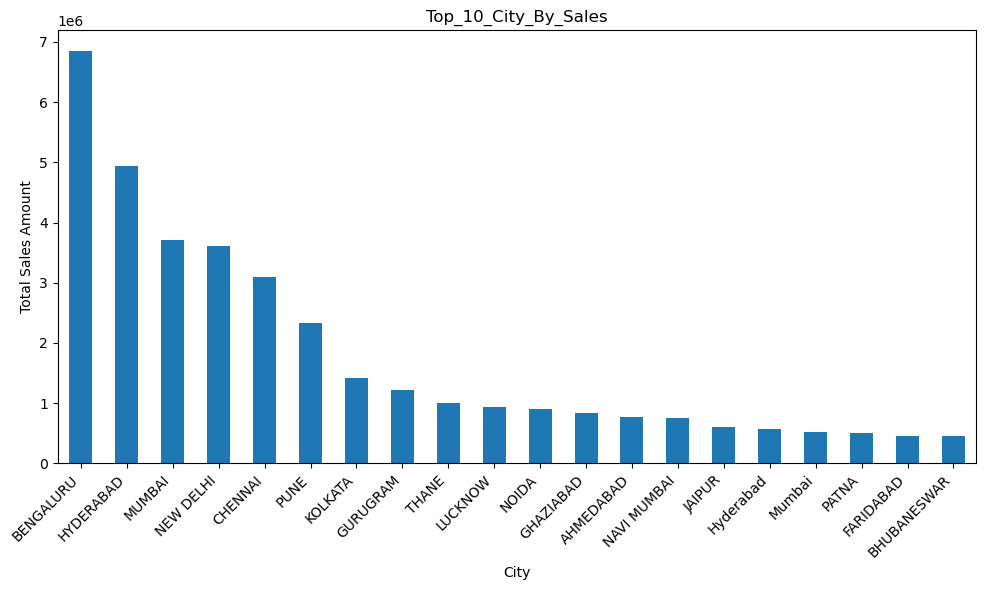

In [179]:
plt.figure(figsize=(10,6))
top_cities.plot(kind='bar')

plt.title("Top_10_City_By_Sales")
plt.xlabel('City')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [183]:
city_orders = df["ship-city"].value_counts().head(20)

print(city_orders)

ship-city
BENGALURU        10685
HYDERABAD         7606
MUMBAI            5867
NEW DELHI         5450
CHENNAI           5130
PUNE              3657
KOLKATA           2245
GURUGRAM          1783
THANE             1607
LUCKNOW           1354
NOIDA             1343
GHAZIABAD         1256
NAVI MUMBAI       1184
AHMEDABAD         1179
JAIPUR             876
Hyderabad          858
Mumbai             825
COIMBATORE         715
VISAKHAPATNAM      714
PATNA              706
Name: count, dtype: int64


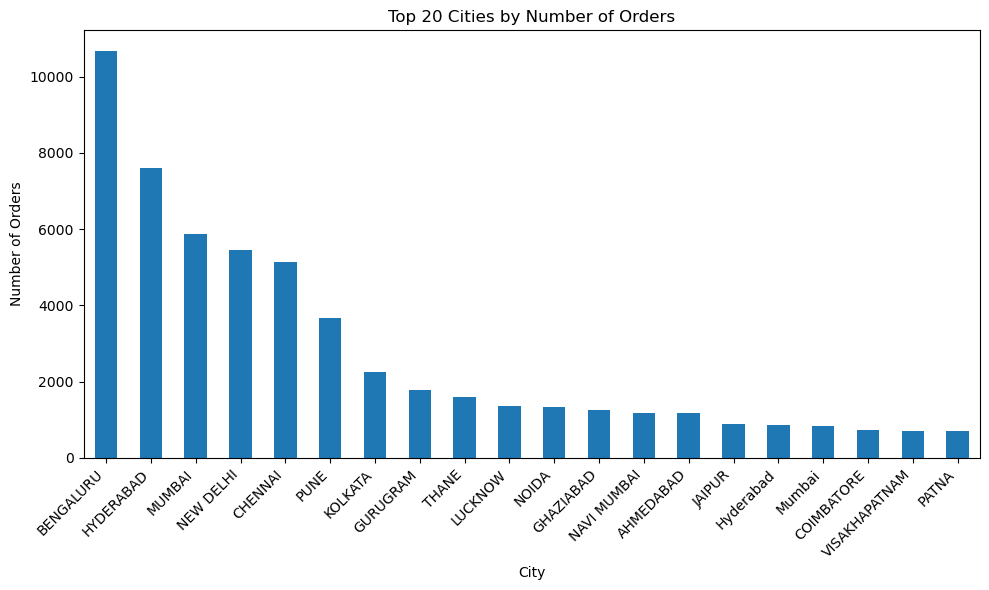

In [184]:
plt.figure(figsize=(10, 6))

city_orders.plot(kind="bar")

plt.title("Top 20 Cities by Number of Orders")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [185]:
category_fulfilment = pd.crosstab(
    df["Category"],
    df["Fulfilment"]
)

print(category_fulfilment)

Fulfilment     Amazon  Merchant
Category                       
Blouse            653       228
Bottom            236       184
Dupatta             3         0
Ethnic Dress      796       297
Saree             124        31
Set             32973     14058
Top              7703      2460
Western Dress    8040      6663
kurta           33093     13607


<Figure size 1000x600 with 0 Axes>

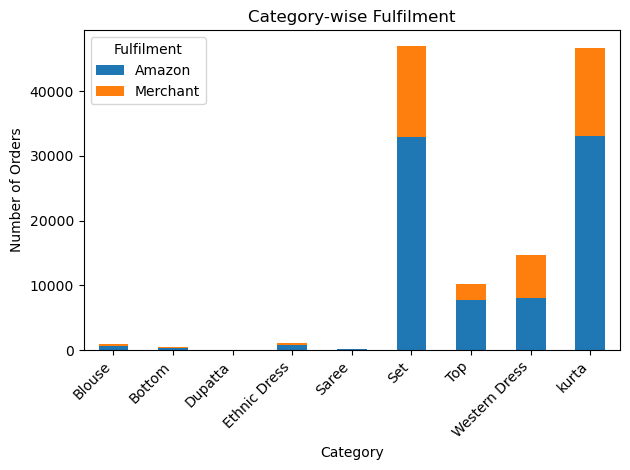

In [189]:
plt.figure(figsize=(10,6))

category_fulfilment.plot(
    kind='bar',
    stacked=True
)

plt.title("Category-wise Fulfilment")
plt.xlabel("Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [192]:
category_fulfilment_pct = pd.crosstab(
    df["Category"],
    df["Fulfilment"],
    normalize="index"
) * 100

print(category_fulfilment_pct.round(2))

Fulfilment     Amazon  Merchant
Category                       
Blouse          74.12     25.88
Bottom          56.19     43.81
Dupatta        100.00      0.00
Ethnic Dress    72.83     27.17
Saree           80.00     20.00
Set             70.11     29.89
Top             75.79     24.21
Western Dress   54.68     45.32
kurta           70.86     29.14


In [193]:
status_sales = df.groupby("Status")["Amount"].sum().sort_values(ascending=False)

print(status_sales)

Status
Shipped                          50314279.0
Shipped - Delivered to Buyer     18645779.0
Cancelled                         6917254.3
Shipped - Returned to Seller      1268015.0
Shipped - Picked Up                661252.0
Pending                            430271.0
Pending - Waiting for Pick Up      192138.0
Shipped - Returning to Seller      107620.0
Shipped - Out for Delivery          26971.0
Shipped - Rejected by Buyer          7295.0
Shipped - Lost in Transit            1997.0
Shipped - Damaged                    1136.0
Name: Amount, dtype: float64


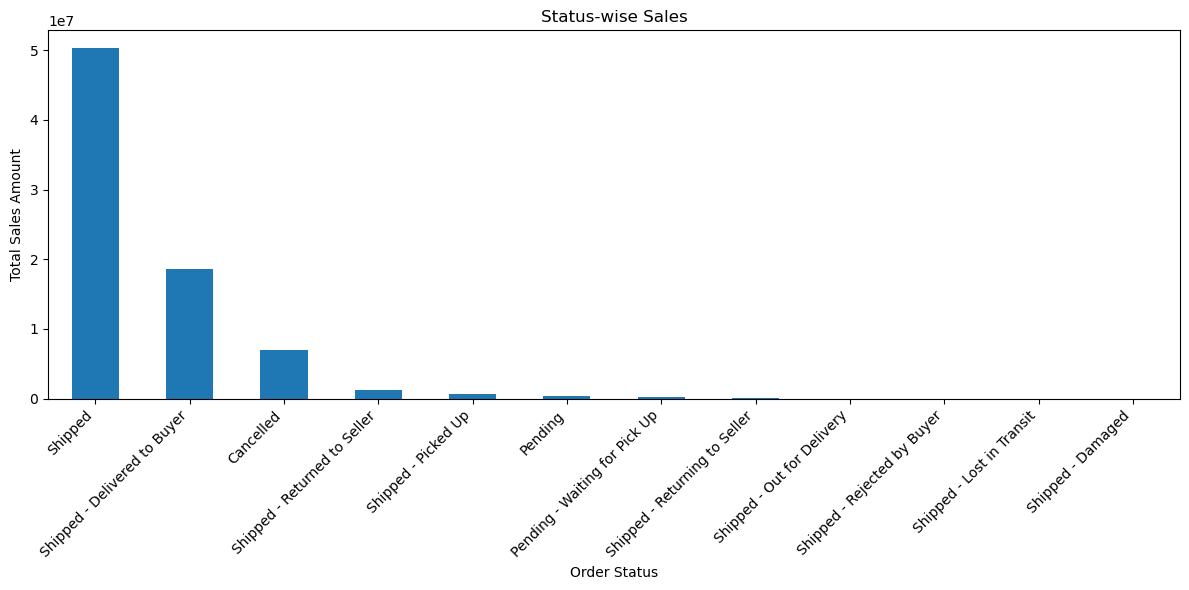

In [194]:
plt.figure(figsize=(12, 6))

status_sales.plot(kind="bar")

plt.title("Status-wise Sales")
plt.xlabel("Order Status")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [195]:
df["Promotion_Status"] = df["promotion-ids"].apply(
    lambda x: "No Promotion" if x == "No Promotion" else "Promotion"
)

print(df["Promotion_Status"].value_counts())

Promotion_Status
Promotion       79458
No Promotion    41691
Name: count, dtype: int64


In [196]:
promotion_sales = df.groupby("Promotion_Status")["Amount"].sum().sort_values(ascending=False)

print(promotion_sales)

Promotion_Status
Promotion       53572713.0
No Promotion    25001294.3
Name: Amount, dtype: float64


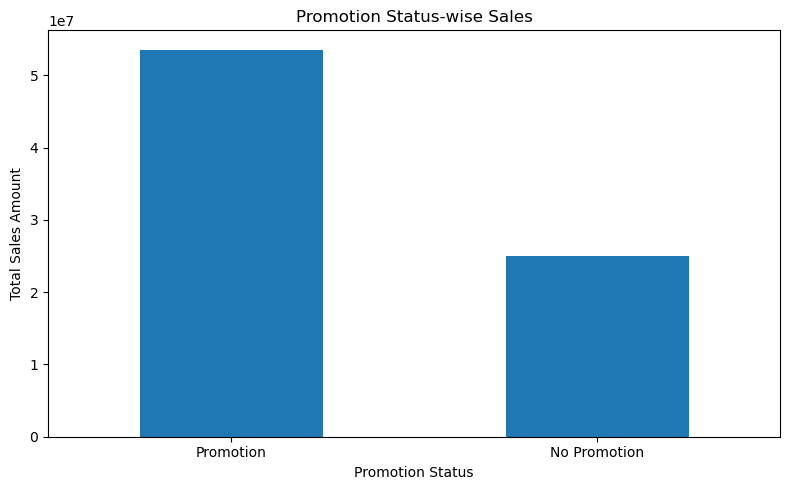

In [197]:
plt.figure(figsize=(8, 5))

promotion_sales.plot(kind="bar")

plt.title("Promotion Status-wise Sales")
plt.xlabel("Promotion Status")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [198]:
promotion_orders = df["Promotion_Status"].value_counts()

print(promotion_orders)
print("\nPercentage:")
print((promotion_orders / len(df) * 100).round(2))

Promotion_Status
Promotion       79458
No Promotion    41691
Name: count, dtype: int64

Percentage:
Promotion_Status
Promotion       65.59
No Promotion    34.41
Name: count, dtype: float64


In [199]:
correlation = df[["Qty", "Amount"]].corr()

print(correlation)

            Qty   Amount
Qty     1.00000  0.06682
Amount  0.06682  1.00000


In [200]:
print("Correlation:", df["Qty"].corr(df["Amount"]))

Correlation: 0.06681991439812726


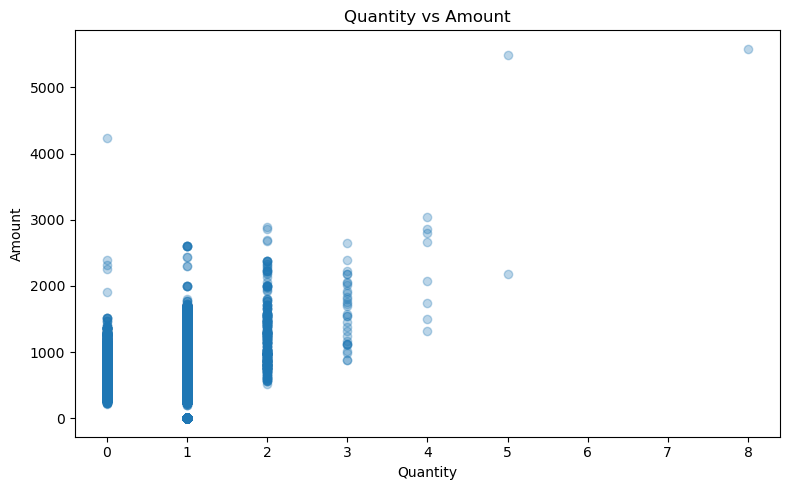

In [201]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Qty"], df["Amount"], alpha=0.3)

plt.title("Quantity vs Amount")
plt.xlabel("Quantity")
plt.ylabel("Amount")

plt.tight_layout()
plt.show()

In [202]:
# Overall Sales aur Orders nikalo
print("Total Orders:", len(df))
print("Total Sales:", df["Amount"].sum())
print("Average Order Value:", df["Amount"].mean())

Total Orders: 121149
Total Sales: 78574007.3
Average Order Value: 648.5733047734608


In [203]:
# Total Quantity
print("Total Quantity:", df["Qty"].sum())

Total Quantity: 116454


In [206]:
# Cancelled Orders %
cancelled_pct = (df["Status"].value_counts(normalize=True)["Cancelled"] * 100)
print(cancelled_pct.round(2))

8.88


In [207]:
# Top Category
print("Top Category:", df["Category"].value_counts().idxmax())

Top Category: Set


In [208]:
# Step 5: Top State
print("Top State:", df["ship-state"].value_counts().idxmax())

Top State: MAHARASHTRA


In [209]:
print("Top Fulfilment:", df["Fulfilment"].value_counts().idxmax())

print("Top Service Level:", df["ship-service-level"].value_counts().idxmax())

print("Top City:", df["ship-city"].value_counts().idxmax())

Top Fulfilment: Amazon
Top Service Level: Expedited
Top City: BENGALURU


In [ ]:
# # Final Business Insights

# ### 1. Order Status

# Shipped orders account for **60.33%** of the total records, while **14.21%** of orders were cancelled. This shows that shipped orders form the majority of the dataset.

# ### 2. Product Category

# **Set** is the most frequently ordered product category, followed by **kurta**. These categories represent a major portion of the overall order volume.

# ### 3. Fulfilment

# **Amazon** is the dominant fulfilment method, accounting for approximately **69.55%** of the records, while Merchant fulfilment accounts for **30.45%**.

# ### 4. Shipping Service

# **Expedited** is the most commonly used shipping service, accounting for **68.71%** of orders, compared with **31.29%** for Standard shipping.

# ### 5. Monthly Trend

# **April** recorded the highest number of orders with **49,054 orders**, followed by **May with 42,028** and **June with 37,689** orders.

# ### 6. Geographical Analysis

# Based on order count, **Maharashtra** is the top state, while **Bengaluru** is the top city in the dataset.

# ### 7. Sales Performance

# The dataset contains approximately **₹7.86 crore** in sales from orders with available Amount values. The **Average Order Value (AOV)** is approximately **₹648.57**.

# ### 8. Quantity and Amount Relationship

# The correlation between **Quantity and Amount is 0.06682**, indicating a **very weak positive linear relationship** between the two variables. This suggests that order quantity alone does not strongly explain the variation in order amount.


In [ ]:
# Conclusion

# The Amazon Sales Analysis provided a detailed understanding of the dataset's sales performance, order patterns, product categories, fulfilment methods, shipping services, and geographical distribution. The analysis showed that **Set** was the most frequently ordered category, **Amazon** was the dominant fulfilment method, and **Expedited** was the most commonly used shipping service.

# The analysis also identified **April** as the month with the highest order volume, while **Maharashtra** had the highest number of orders among states and **Bengaluru** among cities. The dataset recorded approximately **₹7.86 crore in sales** from orders with available Amount values, with an average order value of approximately **₹648.57**.

# Finally, the correlation between Quantity and Amount was **0.06682**, indicating a very weak positive linear relationship between them. Overall, the analysis helped identify important patterns and trends that can be used for better understanding of sales and order performance.
